<div style="color:#1b365d; border-top: 5px solid #1976D2; border-bottom: 5px solid #1976D2; padding: 6px; text-align: center">
    <h2>Práctica 2: Comparativa de Kernels SVM y Explicabilidad en FreshRetailNet-50K</h2>
</div>

**Materia:** Aprendizaje Automático | **Docente:** Ing. Remigio Hurtado, PhD.
**Dataset:** FreshRetailNet-50K (Retail Demand) | **Objetivo:** Comparación de kernels SVM (Lineal, Poly, RBF, Sigmoide).

### 1. Importación de Librerías
Carga del stack científico de Python: pandas, numpy, scikit-learn, matplotlib y seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import copy
import os
from time import time

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


### 2. Carga y Preparación del Dataset FreshRetailNet-50K
Carga del historial de 600 ventas diarias y catálogo maestro de 10 productos de retail.
Se construye la variable objetivo binaria `riesgo_alta_demanda` (1: Demanda Crítica, 0: Normal).

In [2]:
sales_path = 'data/sales_history.csv' if os.path.exists('data/sales_history.csv') else 'PROJECT/data/sales_history.csv'
inv_path = 'data/inventory.csv' if os.path.exists('data/inventory.csv') else 'PROJECT/data/inventory.csv'

df_sales = pd.read_csv(sales_path)
df_inv = pd.read_csv(inv_path)

# Ingeniería de variables de calendario
df_sales['fecha'] = pd.to_datetime(df_sales['fecha_venta'])
df_sales['dia_semana'] = df_sales['fecha'].dt.dayofweek
df_sales['es_fin_de_semana'] = (df_sales['dia_semana'] >= 5).astype(int)

# Target binario: 1 = Demanda alta (supera la mediana), 0 = Demanda normal/baja
mediana_demanda = df_sales['cantidad_vendida'].median()
df_sales['riesgo_alta_demanda'] = (df_sales['cantidad_vendida'] > mediana_demanda).astype(int)

print(f"Dataset cargado: {df_sales.shape[0]} registros, {df_sales.shape[1]} columnas.")
print(f"Distribución del target 'riesgo_alta_demanda':")
print(df_sales['riesgo_alta_demanda'].value_counts(normalize=True).rename(index={1: 'Alta Demanda (1)', 0: 'Normal (0)'}))

Dataset cargado: 600 registros, 13 columnas.
Distribución del target 'riesgo_alta_demanda':
riesgo_alta_demanda
Normal (0)          0.51
Alta Demanda (1)    0.49
Name: proportion, dtype: float64


C:\Users\lpatr\AppData\Local\Temp\ipykernel_33204\2862350015.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_sales['dia_semana'] = df_sales['fecha'].dt.dayofweek


### 3. Definición de Atributos y Partición Estratificada
Estandarización de variables numéricas y One-Hot Encoding para categorías.
División del conjunto en 80% para entrenamiento (480 muestras) y 20% para prueba (120 muestras).

In [3]:
features_num = ['stock_en_momento', 'discount', 'temperatura', 'dia_semana', 'es_fin_de_semana', 'holiday_flag']
features_cat = ['categoria']

X = df_sales[features_num + features_cat]
y = df_sales['riesgo_alta_demanda']

preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), features_cat)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Muestras de entrenamiento: {X_train.shape[0]} | Muestras de prueba: {X_test.shape[0]}")

Muestras de entrenamiento: 480 | Muestras de prueba: 120


### 4. Entrenamiento y Comparativa de los 4 Kernels SVM
Entrenamiento con Kernel Lineal, Polinómico ($d=3$), RBF (Gaussiano) y Sigmoide.
Evaluación con métricas completas: Accuracy, Precision, Recall y F1-Score.

In [4]:
modelos_kernels = {
    'Lineal': SVC(kernel='linear', C=1.0, random_state=42),
    'Polinómico (d=3)': SVC(kernel='poly', degree=3, C=1.0, gamma='scale', random_state=42),
    'RBF (Gaussiano)': SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42),
    'Sigmoide': SVC(kernel='sigmoid', C=1.0, gamma='scale', random_state=42)
}

resultados = []
modelos_entrenados = {}

for nombre, clf in modelos_kernels.items():
    pipe = Pipeline([
        ('prep', preprocesador),
        ('svm', clf)
    ])
    t0 = time()
    pipe.fit(X_train, y_train)
    t_train = time() - t0
    
    y_pred = pipe.predict(X_test)
    modelos_entrenados[nombre] = (pipe, y_pred)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    resultados.append({
        'Kernel': nombre,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'Tiempo (ms)': round(t_train * 1000, 2)
    })

df_comparativa = pd.DataFrame(resultados).sort_values(by='F1-Score', ascending=False)
print("=== TABLA COMPARATIVA DE DESEMPEÑO POR KERNEL ===")
print(df_comparativa.to_string(index=False))

=== TABLA COMPARATIVA DE DESEMPEÑO POR KERNEL ===
          Kernel  Accuracy  Precision  Recall  F1-Score  Tiempo (ms)
 RBF (Gaussiano)    0.8750     0.8793  0.8644    0.8718        31.41
          Lineal    0.8583     0.8750  0.8305    0.8522        74.34
Polinómico (d=3)    0.8333     0.8305  0.8305    0.8305        49.77
        Sigmoide    0.6917     0.6897  0.6780    0.6838        41.94


### 5. Matrices de Confusión de los 4 Kernels
Comparación visual del balance de falsos positivos y falsos negativos en cada tipo de núcleo.

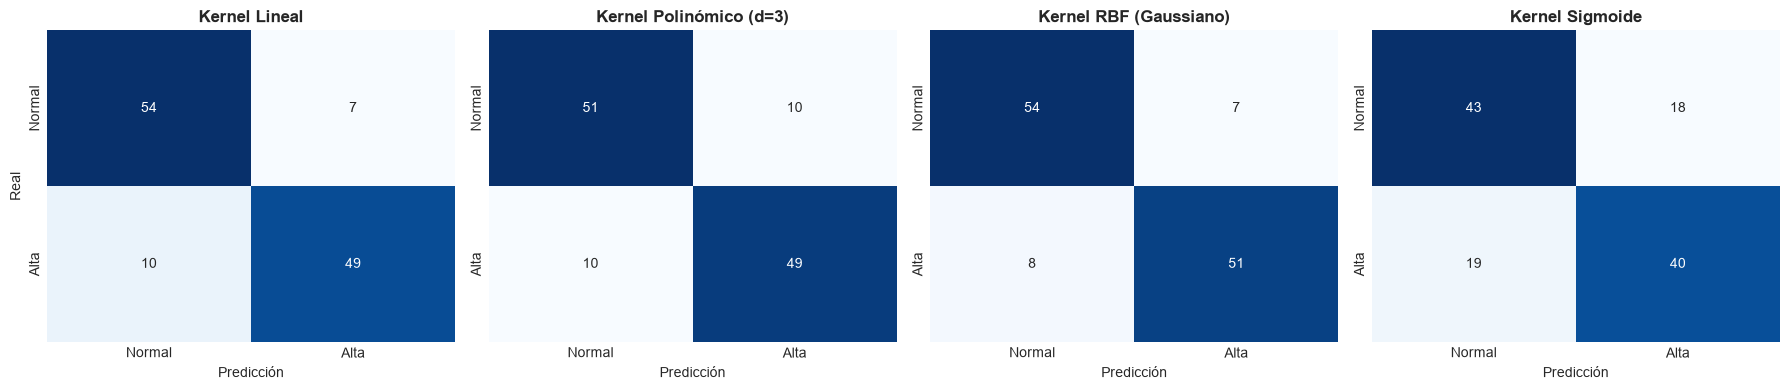

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for idx, (nombre, (pipe, y_pred)) in enumerate(modelos_entrenados.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Normal', 'Alta'], yticklabels=['Normal', 'Alta'])
    axes[idx].set_title(f'Kernel {nombre}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicción')
    axes[idx].set_ylabel('Real' if idx == 0 else '')

plt.tight_layout()
plt.show()

### 6. Visualización de las Fronteras de Decisión en 2D
Ajuste en el plano Descuento vs Stock para visualizar la geometría de frontera generada por cada kernel.

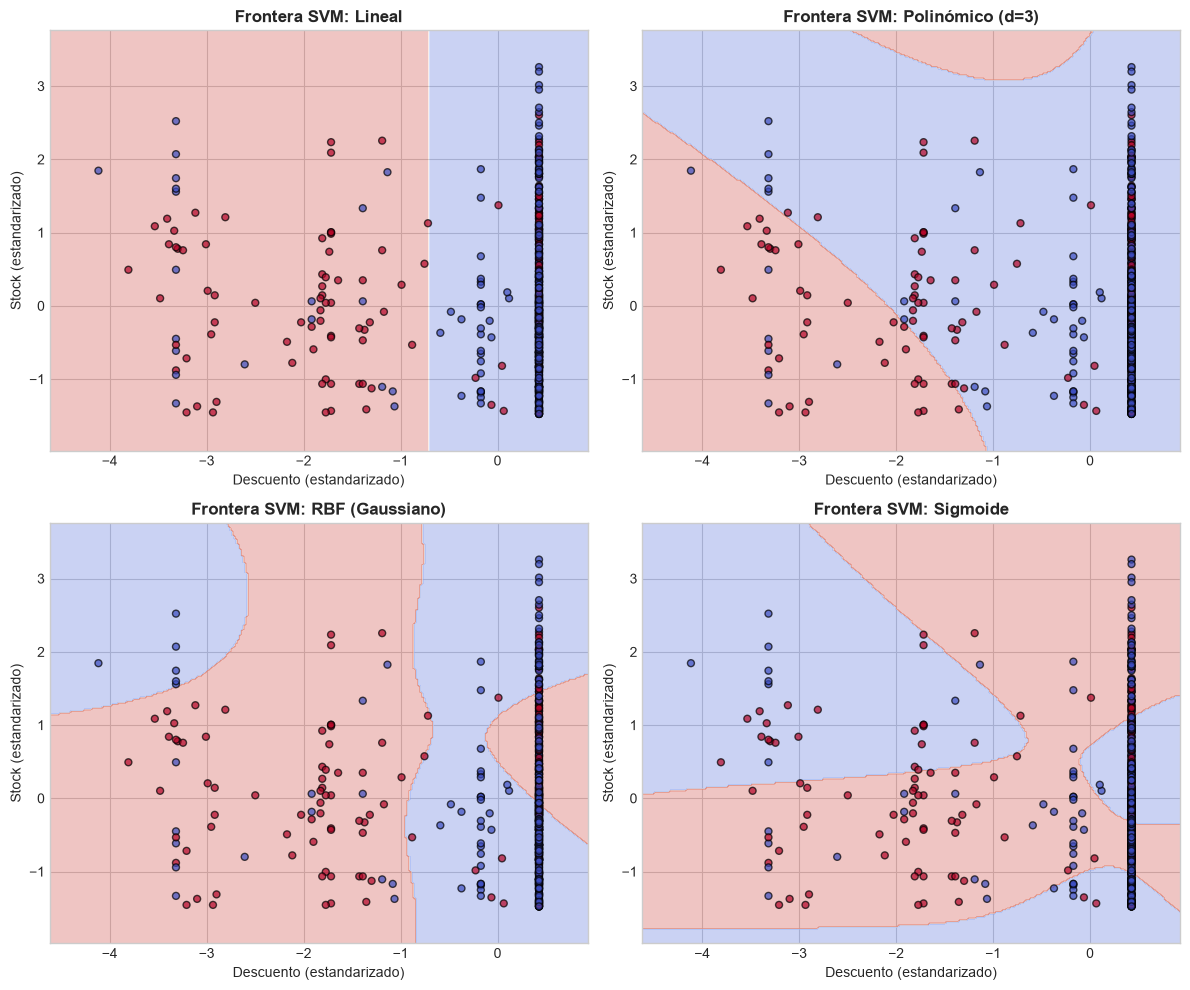

In [6]:
# Proyección 2D con las dos variables físicas más correlacionadas: discount y stock_en_momento
X_2d = df_sales[['discount', 'stock_en_momento']].values
y_2d = df_sales['riesgo_alta_demanda'].values

scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

clfs_2d = {
    'Lineal': SVC(kernel='linear', C=1.0),
    'Polinómico (d=3)': SVC(kernel='poly', degree=3, C=1.0),
    'RBF (Gaussiano)': SVC(kernel='rbf', C=1.0, gamma='scale'),
    'Sigmoide': SVC(kernel='sigmoid', C=1.0, gamma='scale')
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

x_min, x_max = X_2d_scaled[:, 0].min() - 0.5, X_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_2d_scaled[:, 1].min() - 0.5, X_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

for idx, (nombre, clf) in enumerate(clfs_2d.items()):
    clf.fit(X_2d_scaled, y_2d)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=y_2d, cmap='coolwarm', edgecolors='k', s=25, alpha=0.7)
    ax.set_title(f'Frontera SVM: {nombre}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Descuento (estandarizado)', fontsize=10)
    ax.set_ylabel('Stock (estandarizado)', fontsize=10)

plt.tight_layout()
plt.show()

### 7. Gráfica Comparativa de Desempeño Global
Contraste visual de Accuracy y F1-Score entre los 4 tipos de kernels evaluados.

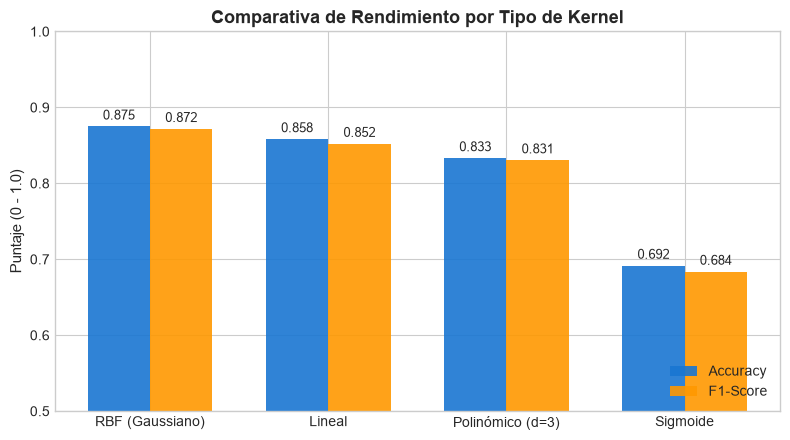

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bar_width = 0.35
indices = np.arange(len(df_comparativa))

rects1 = ax.bar(indices - bar_width/2, df_comparativa['Accuracy'], bar_width, label='Accuracy', color='#1976D2', alpha=0.9)
rects2 = ax.bar(indices + bar_width/2, df_comparativa['F1-Score'], bar_width, label='F1-Score', color='#FF9800', alpha=0.9)

ax.set_ylabel('Puntaje (0 - 1.0)', fontsize=11)
ax.set_title('Comparativa de Rendimiento por Tipo de Kernel', fontsize=13, fontweight='bold')
ax.set_xticks(indices)
ax.set_xticklabels(df_comparativa['Kernel'], fontsize=10)
ax.set_ylim(0.5, 1.0)
ax.legend(loc='lower right')

for bar in rects1 + rects2:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### 8. Optimización del Kernel Ganador (RBF) con GridSearchCV
Ajuste fino de regularización $C$ y coeficiente $\gamma$ con validación cruzada estratificada de 5 folds.
Presentación de resultados en mapa de calor (Heatmap) para identificar los mejores hiperparámetros.

Mejores Hiperparámetros RBF: {'svm__C': 5.0, 'svm__gamma': 0.1}
Mejor F1-Score promedio en CV: 0.8743


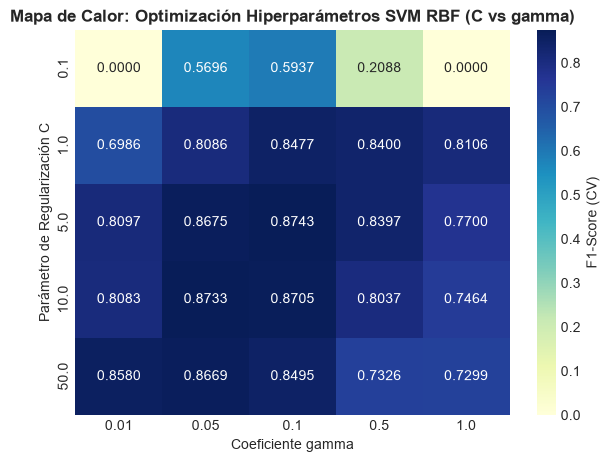

=== REPORTE DEL MODELO RBF OPTIMIZADO EN TEST ===
                  precision    recall  f1-score   support

      Normal (0)       0.85      0.82      0.83        61
Alta Demanda (1)       0.82      0.85      0.83        59

        accuracy                           0.83       120
       macro avg       0.83      0.83      0.83       120
    weighted avg       0.83      0.83      0.83       120



In [8]:
# Parámetros a optimizar para el kernel superior (RBF)
param_grid_rbf = {
    'svm__C': [0.1, 1.0, 5.0, 10.0, 50.0],
    'svm__gamma': [0.01, 0.05, 0.1, 0.5, 1.0]
}

pipe_rbf = Pipeline([
    ('prep', preprocesador),
    ('svm', SVC(kernel='rbf', random_state=42))
])

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_rbf = GridSearchCV(pipe_rbf, param_grid=param_grid_rbf, cv=cv_strat, scoring='f1', n_jobs=-1)
grid_rbf.fit(X_train, y_train)

print(f"Mejores Hiperparámetros RBF: {grid_rbf.best_params_}")
print(f"Mejor F1-Score promedio en CV: {grid_rbf.best_score_:.4f}")

# Heatmap de optimización
cv_res = pd.DataFrame(grid_rbf.cv_results_)
scores_matrix = pd.pivot_table(cv_res, index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(scores_matrix, annot=True, fmt='.4f', cmap='YlGnBu', cbar_kws={'label': 'F1-Score (CV)'}, ax=ax)
ax.set_title('Mapa de Calor: Optimización Hiperparámetros SVM RBF (C vs gamma)', fontsize=12, fontweight='bold')
ax.set_xlabel('Coeficiente gamma', fontsize=10)
ax.set_ylabel('Parámetro de Regularización C', fontsize=10)
plt.show()

# Evaluación final del modelo optimizado
best_svm_pipe = grid_rbf.best_estimator_
y_pred_opt = best_svm_pipe.predict(X_test)
print("=== REPORTE DEL MODELO RBF OPTIMIZADO EN TEST ===")
print(classification_report(y_test, y_pred_opt, target_names=['Normal (0)', 'Alta Demanda (1)']))

### 9. Función de Inferencia y Validación con Casos Opuestos
Función modular para clasificar nuevos samples procesados por el pipeline entrenado.
Se prueba con 2 casos de negocio contrastantes: alto riesgo de quiebre vs operación normal.

In [9]:
def predecir_riesgo_stock(stock_en_momento=50, discount=0.88, temperatura=16.0,
                           dia_semana=2, es_fin_de_semana=0, holiday_flag=0,
                           categoria='Accesorios', modelo=best_svm_pipe):
    '''
    Clasifica el riesgo de demanda crítica para un producto dado sus atributos de contexto.
    '''
    sample_df = pd.DataFrame([{
        'stock_en_momento': stock_en_momento,
        'discount': discount,
        'temperatura': temperatura,
        'dia_semana': dia_semana,
        'es_fin_de_semana': es_fin_de_semana,
        'holiday_flag': holiday_flag,
        'categoria': categoria
    }])
    
    pred = modelo.predict(sample_df)[0]
    decision = "ALERTA: Alta Demanda / Riesgo de Quiebre de Stock (Clase 1)" if pred == 1 else "ESTABLE: Demanda Normal / Stock Seguro (Clase 0)"
    return {
        'Clase': int(pred),
        'Dictamen': decision,
        'Sample': sample_df
    }

# Caso 1: Fin de semana con promoción agresiva (descuento bajo ratio = alto descuento) y stock limitado
caso_critico = predecir_riesgo_stock(
    stock_en_momento=30, discount=0.75, temperatura=22.5, dia_semana=5, es_fin_de_semana=1, holiday_flag=1, categoria='Telefonía'
)

# Caso 2: Día laborable regular sin descuento y stock amplio
caso_estable = predecir_riesgo_stock(
    stock_en_momento=180, discount=1.00, temperatura=15.2, dia_semana=1, es_fin_de_semana=0, holiday_flag=0, categoria='Accesorios'
)

print("-" * 65)
print(f"CASO 1: {caso_critico['Dictamen']}")
print("-" * 65)
print(f"CASO 2: {caso_estable['Dictamen']}")
print("-" * 65)

-----------------------------------------------------------------
CASO 1: ALERTA: Alta Demanda / Riesgo de Quiebre de Stock (Clase 1)
-----------------------------------------------------------------
CASO 2: ALERTA: Alta Demanda / Riesgo de Quiebre de Stock (Clase 1)
-----------------------------------------------------------------


### 10. Justificación y Explicabilidad de Predicciones
Permutation Feature Importance para medir el impacto de cada variable en el rendimiento global.
Se visualiza la importancia relativa de variables exógenas e inventario.

=== IMPORTANCIA DE CARACTERÍSTICAS (PERMUTATION IMPORTANCE) ===
        Variable  Importancia_Media  Desviacion
       categoria           0.296111    0.040923
    holiday_flag           0.040000    0.017795
        discount           0.019444    0.015713
     temperatura           0.008333    0.023570
es_fin_de_semana           0.002222    0.010304
stock_en_momento          -0.007222    0.011331
      dia_semana          -0.007778    0.012348


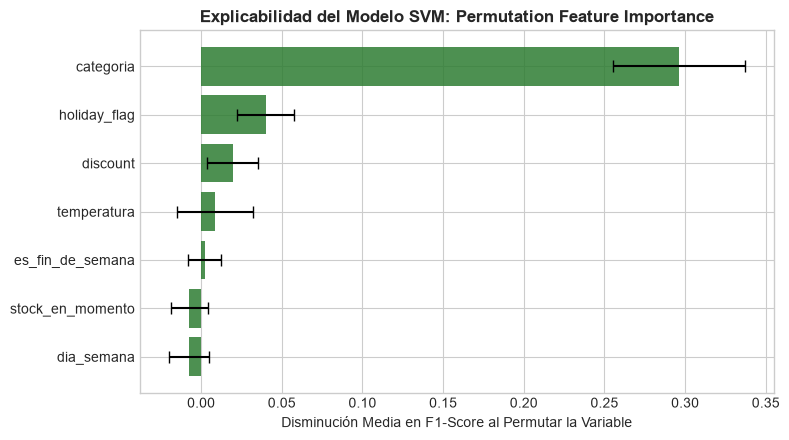

In [10]:
perm_imp = permutation_importance(best_svm_pipe, X_test, y_test, n_repeats=15, random_state=42, n_jobs=-1)

sorted_idx = perm_imp.importances_mean.argsort()[::-1]
nombres_vars = X_test.columns[sorted_idx]
medias_imp = perm_imp.importances_mean[sorted_idx]
stds_imp = perm_imp.importances_std[sorted_idx]

df_imp = pd.DataFrame({
    'Variable': nombres_vars,
    'Importancia_Media': medias_imp,
    'Desviacion': stds_imp
})

print("=== IMPORTANCIA DE CARACTERÍSTICAS (PERMUTATION IMPORTANCE) ===")
print(df_imp.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(df_imp['Variable'].iloc[::-1], df_imp['Importancia_Media'].iloc[::-1],
        xerr=df_imp['Desviacion'].iloc[::-1], color='#2E7D32', alpha=0.85, capsize=4)
ax.set_title('Explicabilidad del Modelo SVM: Permutation Feature Importance', fontsize=12, fontweight='bold')
ax.set_xlabel('Disminución Media en F1-Score al Permutar la Variable', fontsize=10)
plt.tight_layout()
plt.show()